# 01 · Business overview — how much, when, and from whom

**Questions answered:** what does the business earn, when does it earn it, and how
concentrated is that revenue across customers?

**Data:** gold layer (`fact_orders`, `fact_order_lines`), 2009-12-01 → 2011-12-09.
**Grain:** revenue is summed at line grain; behavioural metrics use one row per
*purchase occasion* (customer-day).
**Definitions:** every metric is defined in
[`docs/metrics_dictionary.md`](../docs/metrics_dictionary.md) before it is computed.

All tables are produced by `uv run python -m hub.analytics.report` and loaded from
`reports/tables/`. The notebook does not re-derive them, so its numbers and
`reports/analysis.json` cannot drift apart.


In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TABLES = ROOT / "reports" / "tables"
FIGURES = ROOT / "reports" / "figures"
analysis = json.loads((ROOT / "reports" / "analysis.json").read_text())


def gbp(value: float, digits: int = 0) -> str:
    return f"£{value:,.{digits}f}"

## Headline numbers

In [2]:
r = analysis["revenue"]
w = analysis["data_window"]
rp = analysis["repeat_purchase"]

headline = pd.DataFrame(
    [
        ("Gross revenue", gbp(r["gross_revenue"]), "non-reversal lines"),
        ("Reversals", gbp(r["reversal_revenue"]), "cancellation + adjustment lines"),
        ("Net revenue", gbp(r["net_revenue"]), "gross + reversals"),
        ("Invoices", f"{w['orders']:,}", "distinct invoice_no"),
        ("Identified customers", f"{w['customers']:,}", "not null customer_id"),
        ("Buyers", f"{rp['buyers']:,}", "with ≥1 purchase occasion"),
        ("AOV (product orders)", gbp(r["aov"], 2), "product revenue / product orders"),
        ("Median order value", gbp(r["median_product_order_value"], 2), "robust to tails"),
        ("ARPU (2-year window)", gbp(analysis["arpu"]), "net revenue per buyer"),
        ("Repeat purchase rate", f"{rp['rate']:.1%}", "≥2 purchase occasions"),
    ],
    columns=["metric", "value", "definition"],
)
display(headline.set_index("metric"))

,value,definition
metric,,
Gross revenue,"£20,465,198",non-reversal lines
Reversals,"£-1,609,665",cancellation + adjustment lines
Net revenue,"£18,855,534",gross + reversals
Invoices,"53,628",distinct invoice_no
Identified customers,"5,942",not null customer_id
Buyers,"5,881",with ≥1 purchase occasion
AOV (product orders),£438.98,product revenue / product orders
Median order value,£255.76,robust to tails
ARPU (2-year window),"£2,780",net revenue per buyer


The gap between AOV (£439) and the median order (£256) is the first signal in the
data: a small number of very large wholesale invoices pull the mean up by 71%. Both
numbers are reported from here on — a mean alone would misprice a typical retail
basket, and a median alone would understate total cash.

The 71.2% repeat rate counts *occasions*, not invoices: 3,008 customer-days contain
more than one invoice, so invoice-grain counting would overstate repeat behaviour.


## Revenue over time

Complete months: 24 (2009-12 → 2011-11)
Peak:   2011-11  £1,456,146
Trough: 2011-04  £492,368
Peak / trough ratio: 2.96x


,net_revenue,gross_revenue,product_revenue,orders,buyers,is_complete_month
month,,,,,,
2011-06,689977.0,760547.0,723845.0,2012,991,True
2011-07,680157.0,718076.0,676812.0,1927,949,True
2011-08,681386.0,746779.0,701290.0,1737,935,True
2011-09,1017597.0,1056435.0,1011340.0,2327,1266,True
2011-10,1069368.0,1151264.0,1061701.0,2637,1364,True
2011-11,1456146.0,1503867.0,1427125.0,3462,1665,True


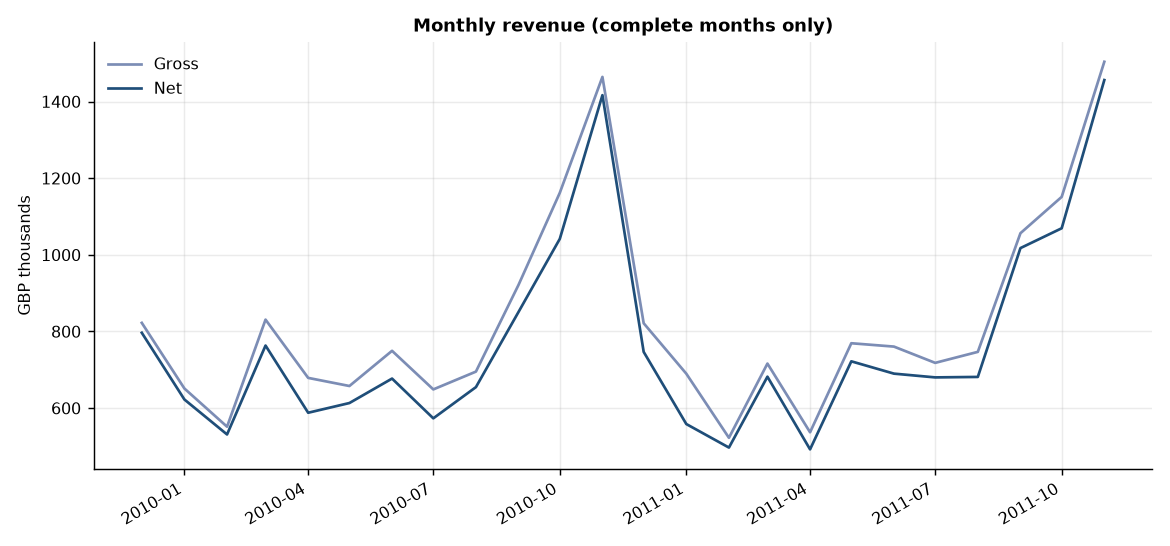

In [3]:
monthly = pd.read_csv(TABLES / "monthly_revenue.csv", parse_dates=["month"])
complete = monthly.loc[monthly["is_complete_month"]].copy()
complete["month"] = complete["month"].dt.strftime("%Y-%m")

peak = complete.loc[complete["net_revenue"].idxmax()]
trough = complete.loc[complete["net_revenue"].idxmin()]
first, last = complete["month"].iloc[0], complete["month"].iloc[-1]
print(f"Complete months: {len(complete)} ({first} → {last})")
print(f"Peak:   {peak['month']}  {gbp(peak['net_revenue'])}")
print(f"Trough: {trough['month']}  {gbp(trough['net_revenue'])}")
print(f"Peak / trough ratio: {peak['net_revenue'] / trough['net_revenue']:.2f}x")
display(complete.tail(6).set_index("month").round(0))
display(Image(filename=str(FIGURES / "monthly_revenue.png")))

The 2011-12 month is excluded: it stops on 9 December, so its total is a partial
month, not a collapse. The 2009-12 cohort is left-censored for retention purposes
for the same reason (see notebook 02). The two December peaks are genuine — this is a
gift retailer.


## Weekly rhythm

,n_days,zero_days,total_revenue,mean_revenue,index_vs_mean
day_name,,,,,
Monday,105,11,3273178.566,31173.129200,1.221760
Tuesday,106,2,3724295.592,35134.864075,1.377032
Wednesday,106,2,3278445.133,30928.727670,1.212182
Thursday,106,3,3886516.902,36665.253792,1.437012
Friday,106,7,2904261.243,27398.690972,1.073830
Saturday,105,104,9803.050,93.362381,0.003659
Sunday,105,6,1779033.212,16943.173448,0.664049


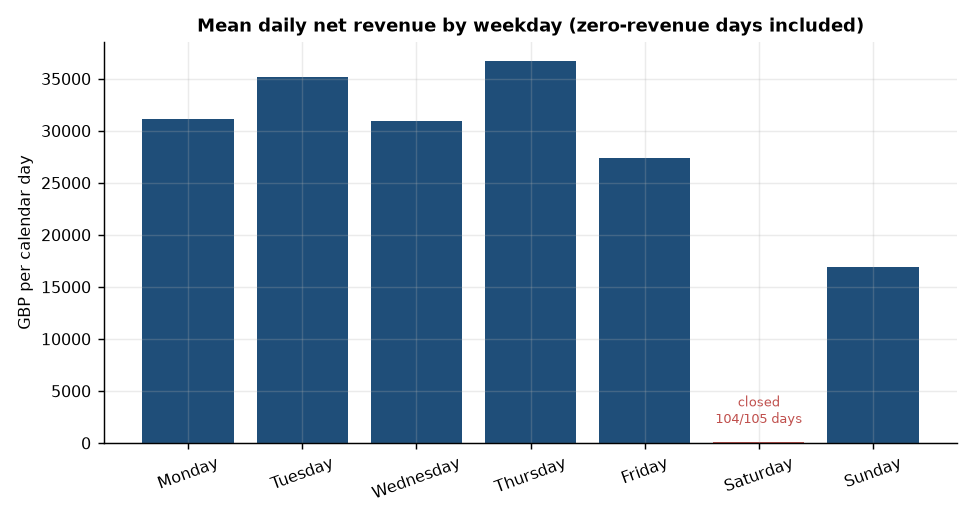

In [4]:
dow = pd.read_csv(TABLES / "day_of_week.csv")
display(dow.set_index("day_name"))
display(Image(filename=str(FIGURES / "day_of_week.png")))

Saturday is not a low-revenue day, it is effectively **closed**: 104 of 105 Saturdays
have zero revenue. The one trading Saturday makes the Saturday mean look non-zero
(£93), which is why the report flags low-activity days by zero-day share rather than by
mean revenue. Thursday is the strongest day (1.44× the overall mean); Sunday trades at
0.66×.


## Trading hours

Peak hour: 12:00 — 13.9% of ordinary revenue
09:00–17:59 share: 94.9%


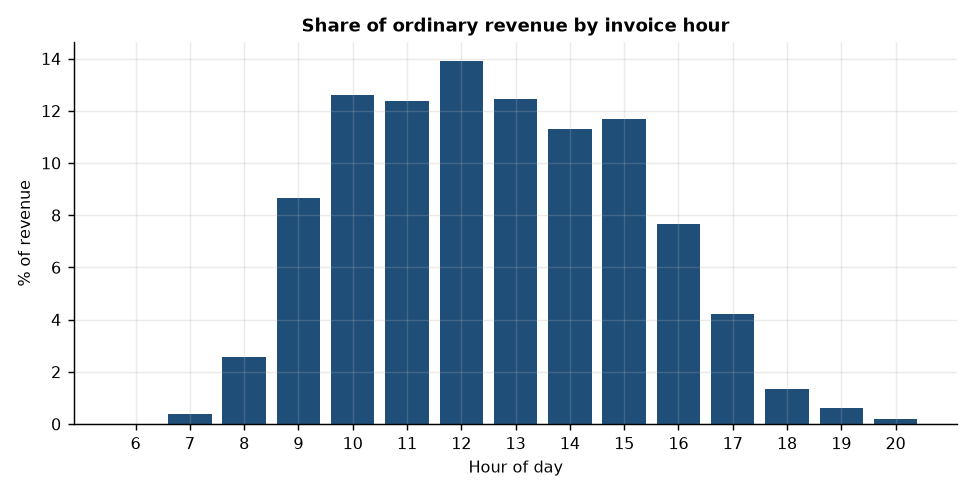

In [5]:
hours = pd.read_csv(TABLES / "hour_effect.csv")
peak_hour = hours.loc[hours["revenue_share"].idxmax()]
peak_share = peak_hour["revenue_share"]
nine_to_five = hours.loc[hours["hour"].between(9, 17), "revenue_share"].sum()
print(f"Peak hour: {int(peak_hour['hour'])}:00 — {peak_share:.1%} of ordinary revenue")
print(f"09:00–17:59 share: {nine_to_five:.1%}")
display(Image(filename=str(FIGURES / "hour_effect.png")))

Trading is a business-hours phenomenon: 94.9% of revenue is invoiced between 09:00 and
17:59, with noon the single busiest hour. Staffing, customer service and campaign sends
should be weighted to that window; the 06:00–08:00 tail is under 3%.


## Q4 and the seasonal cycle

,q4_days,non_q4_days,q4_mean,non_q4_mean,lift,q4_complete
year,,,,,,
2009,31,0,25698.339,NaN,NaN,False
2010,92,273,34838.113,21518.232,1.619,True
2011,70,273,42260.473,22055.195,1.916,False


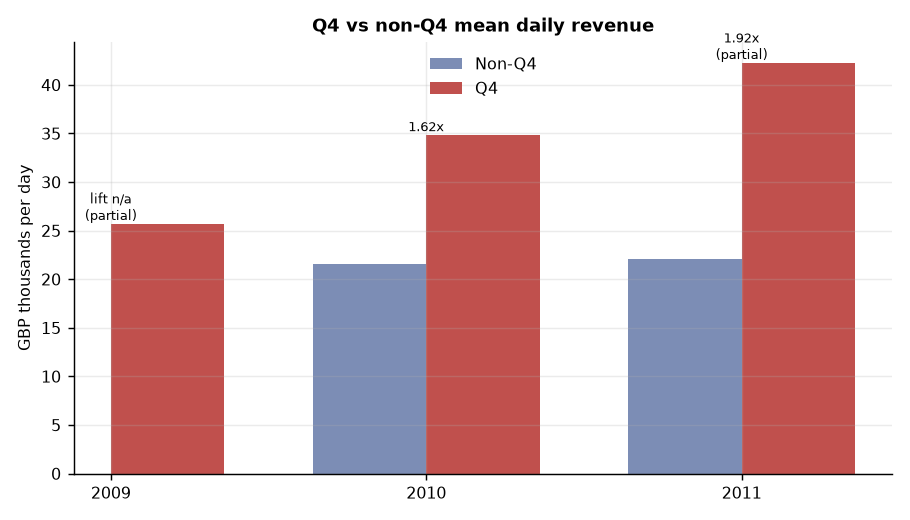

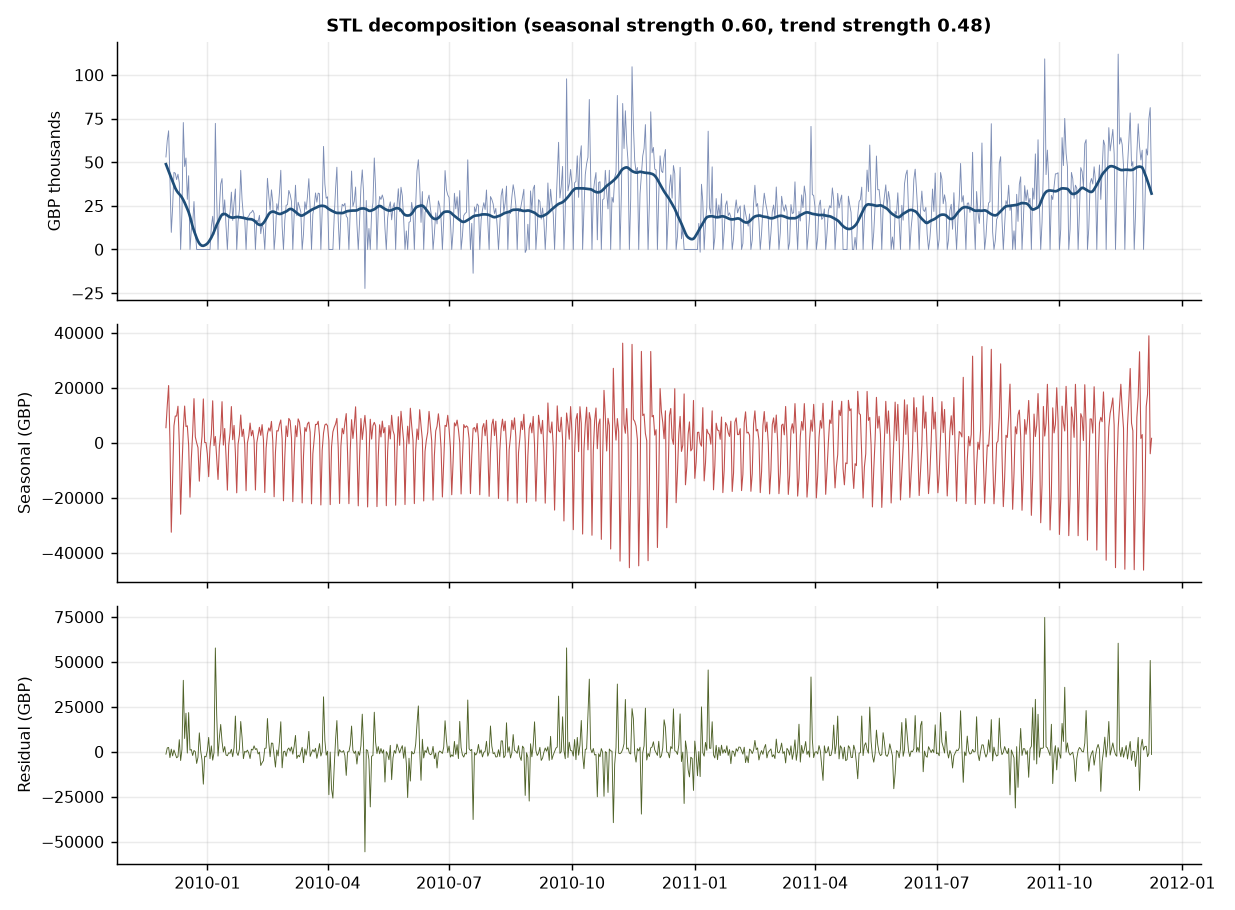

In [6]:
q4 = pd.read_csv(TABLES / "q4_lift.csv")
display(q4.set_index("year").round(3))
display(Image(filename=str(FIGURES / "q4_lift.png")))
display(Image(filename=str(FIGURES / "stl_decomposition.png")))

The Q4 lift is 1.62× in the only complete year (2010) and 1.92× for the partial 2011
Q4. 2009 has no non-Q4 baseline (data starts in December), so its lift is deliberately
`NaN` rather than 1.0. STL confirms the pattern is real and not a trend artefact:
seasonal strength 0.60 versus trend strength 0.48 on a zero-filled daily series.


## Customer concentration

Top   1% of customers (  59):  31.3% of net revenue
Top   5% of customers ( 297):  51.5% of net revenue
Top  10% of customers ( 594):  63.7% of net revenue
Top  20% of customers (1,188):  77.4% of net revenue
Gini coefficient: 0.740
Customers needed for 80% of revenue: 1,353 (22.8%)


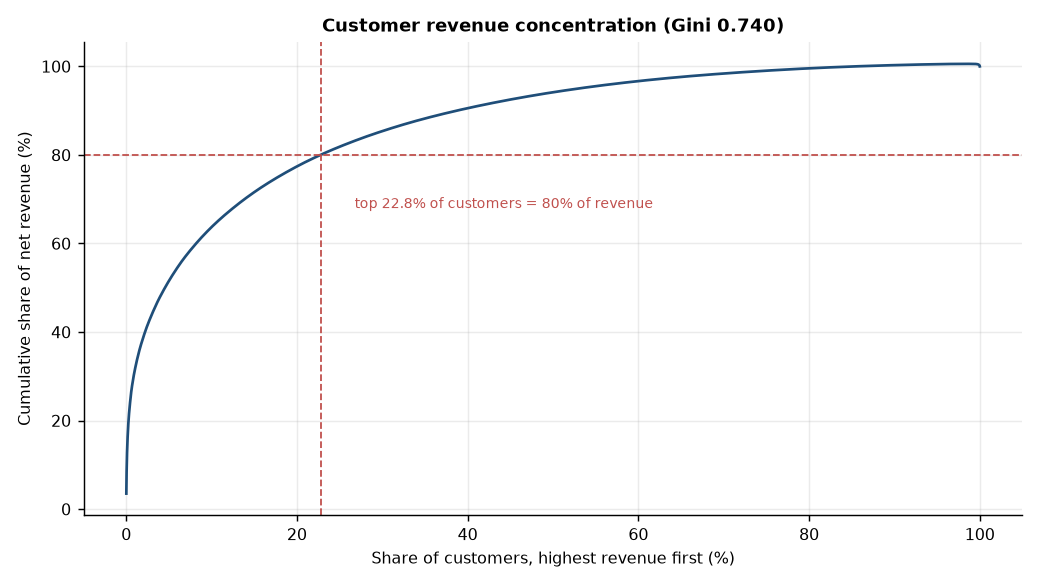

In [7]:
pareto = pd.read_csv(TABLES / "customer_pareto.csv")
for share in (0.01, 0.05, 0.10, 0.20):
    n = max(1, int(len(pareto) * share))
    cumulative = pareto["cumulative_revenue_share"].iloc[n - 1]
    print(f"Top {share:>4.0%} of customers ({n:>4,}): {cumulative:>6.1%} of net revenue")
print(f"Gini coefficient: {analysis['customer_concentration']['gini']:.3f}")
print(
    "Customers needed for 80% of revenue:",
    f"{analysis['customer_concentration']['pareto']['n_needed']:,}",
    f"({analysis['customer_concentration']['pareto']['share_of_items']:.1%})",
)
display(Image(filename=str(FIGURES / "customer_pareto.png")))

Revenue is heavily concentrated: the top 1% of customers produce 31.3% of net revenue
and 22.8% of customers produce 80%. Gini is 0.740 (1.0 would be one customer). 83
customers have net-negative lifetime revenue — refunds exceed purchases — and are
clipped to zero for the Gini calculation, which is why the count is reported alongside it.


## So what?

1. **Plan the year around Q4.** Q4 runs at 1.6–1.9× baseline daily revenue, and the
   November peak (£1.46M) is 2.96× the April trough (£0.49M). Inventory, staffing and
   paid acquisition should follow that curve, not a flat monthly budget.
2. **Do not staff Saturday.** 104 of 105 Saturdays are zero-revenue; Thursday alone
   carries 1.44× the average day. Weekend cover should be Sunday-only.
3. **Concentrate service and campaigns in business hours.** 94.9% of revenue is invoiced
   09:00–17:59, peaking at noon.
4. **Treat the top 1% as an account portfolio, not a segment.** 59 customers generate
   31.3% of revenue; losing a handful of wholesale accounts moves the annual total by
   millions, while a churn-reduction campaign aimed at the whole base would spend most
   of its effort on customers who contribute a few percent.
5. **Report mean and median order value together.** The mean (£439) is 1.72× the median
   (£256); quoting only the mean overstates a typical basket and understates the
   wholesale tail that actually funds the business.


## Limitations

- Twelve months of 2009 and the first nine days of 2011-12 are partial and excluded
  from month-level comparisons.
- Revenue is GBP converted at source; no FX adjustment is applied across the window.
- Concentration is measured on realized net revenue, not on forward-looking value;
  notebook 02 shows how much of that concentration persists.
